# California Z500/T700: event detection using the standard deviation of the distribution of 5-day means

**Motivation.** `CA_z500_t700_methodA_vs_methodB.ipynb` (Sections 3-4) defines a "large
event" as >= `MIN_DURATION` **consecutive days** each individually at/above a sigma
threshold, where sigma is the climatological standard deviation of **daily** values.
This notebook asks instead: what *is* the standard deviation of the distribution of
**5-day means**, and does standardizing by that number give a more useful ranking of
"large events"?

**Revision history.** This version incorporates a software-engineering review and a
statistics review of the first draft:

- All climatology/event-detection logic now lives in **`ca_blocking_lib.py`**
  (imported below) instead of being copy-pasted per notebook -- a fix made once is
  picked up everywhere that imports it, including `CA_z500_t700_methodA_vs_methodB.ipynb`.
- **Fixed a mean/variance inconsistency**: the original code detrended the
  climatological *mean* but computed the climatological *std* from the raw,
  trend-contaminated values -- `lib.standardize_with_trend` now estimates both from
  the same detrended baseline, and prints the size of the correction.
- **Theil-Sen trend** (robust to the annual series being short and
  autocorrelated) is fit alongside OLS, with a confidence interval.
- A **year-block bootstrap CI** is reported for the "X% narrower" std comparison
  instead of a single point estimate.
- A **percentile-based threshold** is run alongside the parametric sigma threshold,
  since both variables are measurably skewed (see the climate-science review).
- **`MAX_GAP` is now justified empirically** via a runs-estimator of the extremal
  index across a range of gap tolerances, rather than asserted as a constant.
- Event records now include `second_peak_sanom` next to `peak_sanom`, and the
  ranked-events section calls out the **winner's-curse** selection bias in picking
  "top 10 by peak" out of ~100+ candidates.
- Misc: fixed a hardcoded magic-number threshold, added an explicit `display` import,
  vectorized the event date-overlap check, closed the dataset handle at the end, and
  added sanity assertions after each event-detection step.

## 0. Setup

In [1]:
import sys
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

sys.path.insert(0, str(Path.cwd()))
import ca_blocking_lib as lib

DATA_DIR = Path('/glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking')
YEARS = list(range(1990, 2026))  # 1990-2025 inclusive, excludes 2026
CLIM_WINDOW = 5                  # +/- calendar days pooled across years for climatology
ROLL_WINDOW = 5                  # width of the running mean that defines a "5-day mean"
                                  # (independent of CLIM_WINDOW even though both happen
                                  # to be 5 right now -- one controls climatology
                                  # pooling, the other controls the smoothing window)
MAX_GAP = 1                      # max sub-threshold calendar days tolerated within an
                                  # event; see Section 8 for the empirical justification
THRESHOLDS = [1, 2, 3]           # standard deviations OF THE RELEVANT DISTRIBUTION --
                                  # daily-value sigma in Section 3, 5-day-mean sigma from
                                  # Section 4 onward
SIGN = 1                         # +1 = ridging/warm (as requested); -1 = troughs/cold
VARS = [('z500', '500 hPa height (ridging)'), ('t700', '700 hPa temperature (warm)')]

print(f'CLIM_WINDOW={CLIM_WINDOW} (climatology pooling), ROLL_WINDOW={ROLL_WINDOW} (smoothing window)')

CLIM_WINDOW=5 (climatology pooling), ROLL_WINDOW=5 (smoothing window)


## 1. Load the CA-box daily gridded data

In [2]:
files = [DATA_DIR / f'z500_t700_ca_{y}.nc' for y in YEARS]
missing = [f.name for f in files if not f.exists()]
if missing:
    raise FileNotFoundError(
        f'{len(missing)} year file(s) missing from {DATA_DIR}: {missing[:5]}...\n'
        'Run job_array_get_z500_t700_ca.pbs first (see get_z500_t700_ca.py).'
    )

ds = xr.open_mfdataset(files, combine='by_coords')
weights = np.cos(np.deg2rad(ds.latitude))  # cosine-latitude area weights
ds

ERROR 1: PROJ: proj_create_from_database: Open of /glade/u/apps/opt/miniforge/envs/npl-2026a/share/proj failed


<xarray.Dataset> Size: 67MB
Dimensions:    (time: 4329, latitude: 43, longitude: 45)
Coordinates:
  * time       (time) datetime64[ns] 35kB 1990-01-01 1990-01-02 ... 2025-04-30
  * latitude   (latitude) float64 344B 42.5 42.25 42.0 41.75 ... 32.5 32.25 32.0
  * longitude  (longitude) float64 360B 235.0 235.2 235.5 ... 245.5 245.8 246.0
Data variables:
    z500       (time, latitude, longitude) float32 34MB dask.array<chunksize=(120, 43, 45), meta=np.ndarray>
    t700       (time, latitude, longitude) float32 34MB dask.array<chunksize=(120, 43, 45), meta=np.ndarray>
Attributes: (12/18)
    long_name:                     Geopotential
    short_name:                    z
    units:                         m
    original_format:               WMO GRIB 1 with ECMWF local table
    ecmwf_local_table:             128
    ecmwf_parameter:               129
    ...                            ...
    rda_dataset_group:             ERA5 atmospheric pressure level analysis [...
    number_of_significant_digits:  7
    description:                   daily-mean 500 hPa geopotential height ove...
    script:                        get_z500_t700_ca.py
    box:                           lat 32.0-42.5, lon 235.0-246.0 (California)
    months:                        Jan-Apr

## 2. Shared helper functions

Imported from `ca_blocking_lib.py` (see Setup): `climatology_dict`, `lookup_climatology`,
`percentile_climatology`, `fit_year_trend`, `standardize_with_trend`,
`rolling_mean_per_year`, `find_events`, `extremal_index_runs`, `match_rate`, and
`bootstrap_climatology_std`. That module is also importable from any other notebook
in this directory -- see its docstring for details on each function.

## 3. Baseline: Method A daily-anomaly events

Reproduces Method A from `CA_z500_t700_methodA_vs_methodB.ipynb` (average-then-
standardize, year-detrended, >= 5 consecutive days) so this notebook has its own
baseline to compare against. Uses `lib.standardize_with_trend`, which reports the
size of the mean/std-consistency fix for each variable as it runs.

In [3]:
z500_box = ds.z500.weighted(weights).mean(dim=('latitude', 'longitude')).compute()
t700_box = ds.t700.weighted(weights).mean(dim=('latitude', 'longitude')).compute()

df = pd.DataFrame(
    {'z500': z500_box.values, 't700': t700_box.values},
    index=pd.to_datetime(ds.time.values),
).sort_index()
df = df[df.index.month.isin([1, 2, 3, 4])]  # keep Jan-Apr only

for col in ['z500', 't700']:
    sanom, diag = lib.standardize_with_trend(df.index, df[col].values, window=CLIM_WINDOW, label=f'{col} (daily)')
    df[f'{col}_clim_std'] = diag['clim_std']
    df[f'{col}_sanom'] = sanom

events_A = []
for col, label in VARS:
    sanom = df[f'{col}_sanom'].values
    for thr in THRESHOLDS:
        ev = lib.find_events(df.index, sanom, threshold=thr, min_duration=5, sign=SIGN, max_gap=MAX_GAP)
        ev.insert(0, 'threshold_sd', thr)
        ev.insert(0, 'variable', label)
        events_A.append(ev)

events_methodA = pd.concat(events_A, ignore_index=True)
events_methodA = events_methodA.sort_values(['variable', 'threshold_sd', 'start_date']).reset_index(drop=True)
assert len(events_methodA) > 0, 'no Method A baseline events found -- check THRESHOLDS/data before continuing'
print(f'Method A baseline: {len(events_methodA)} events found (>= 5 consecutive days, gap tolerance {MAX_GAP} day(s))')
events_methodA.groupby(['variable', 'threshold_sd']).agg(
    n_events=('duration_days', 'size'),
    mean_duration=('duration_days', 'mean'),
    max_duration=('duration_days', 'max'),
)

z500 (daily): Theil-Sen trend = +8.354/decade (90% CI [+2.573, +13.634]/decade); OLS = +7.405/decade (p=0.045, r=0.34)
z500 (daily): clim_std, naive (trend-contaminated) = 89.5483, detrended (corrected) = 89.2259 (+0.360% difference)
t700 (daily): Theil-Sen trend = +0.230/decade (90% CI [-0.011, +0.432]/decade); OLS = +0.204/decade (p=0.168, r=0.23)
t700 (daily): clim_std, naive (trend-contaminated) = 3.7554, detrended (corrected) = 3.7494 (+0.161% difference)
Method A baseline: 95 events found (>= 5 consecutive days, gap tolerance 1 day(s))


,,n_events,mean_duration,max_duration
variable,threshold_sd,,,
500 hPa height (ridging),1,48,6.895833,12.0
700 hPa temperature (warm),1,47,7.638298,18.0


## 4. The distribution of 5-day means, and its standard deviation

Build a centered 5-day running mean of the raw box-averaged series, then treat *that*
series -- not the daily series -- as the thing to standardize: `lib.standardize_with_trend`
applied to the rolling-mean series gives a per-calendar-day mean and standard
deviation **of the distribution of 5-day means**, with the mean/std-consistency fix
applied here too.

In [4]:
df_roll = pd.DataFrame({
    'z500': lib.rolling_mean_per_year(df['z500'], ROLL_WINDOW),
    't700': lib.rolling_mean_per_year(df['t700'], ROLL_WINDOW),
}, index=df.index).dropna()  # drops the (window-1)/2 edge days of each year's record

for col in ['z500', 't700']:
    sanom, diag = lib.standardize_with_trend(df_roll.index, df_roll[col].values, window=CLIM_WINDOW,
                                              label=f'{col} (5-day mean)')
    df_roll[f'{col}_clim_std'] = diag['clim_std']
    df_roll[f'{col}_sanom'] = sanom

print()
print('Standard deviation of the distribution of values, physical units, '
      'averaged across all calendar-day windows (both now computed on the '
      'same detrended basis -- see the per-variable fix-size printout above):')
for col, unit in [('z500', 'm'), ('t700', 'K')]:
    daily_std = df[f'{col}_clim_std'].mean()
    fiveday_std = df_roll[f'{col}_clim_std'].mean()
    pct = 100 * (1 - fiveday_std / daily_std)
    print(f'  {col}: daily = {daily_std:.3f} {unit}, 5-day-mean = {fiveday_std:.3f} {unit} ({pct:.1f}% narrower)')

z500 (5-day mean): Theil-Sen trend = +7.849/decade (90% CI [+2.996, +13.670]/decade); OLS = +7.428/decade (p=0.048, r=0.33)
z500 (5-day mean): clim_std, naive (trend-contaminated) = 72.2909, detrended (corrected) = 71.8800 (+0.568% difference)
t700 (5-day mean): Theil-Sen trend = +0.213/decade (90% CI [-0.022, +0.429]/decade); OLS = +0.204/decade (p=0.178, r=0.23)
t700 (5-day mean): clim_std, naive (trend-contaminated) = 3.0664, detrended (corrected) = 3.0586 (+0.253% difference)

Standard deviation of the distribution of values, physical units, averaged across all calendar-day windows (both now computed on the same detrended basis -- see the per-variable fix-size printout above):
  z500: daily = 89.226 m, 5-day-mean = 71.880 m (19.4% narrower)
  t700: daily = 3.749 K, 5-day-mean = 3.059 K (18.4% narrower)


## 5. How much narrower, with a bootstrap confidence interval

A single point estimate ("19% narrower") has no attached uncertainty. This resamples
the 36 years with replacement (same draw sequence for the daily and 5-day-mean series,
via a shared `random_state`, so the two bootstrap distributions are paired rather than
independent) and reports a confidence interval on the percent-narrower statistic.

In [5]:
N_BOOT = 200
for col, unit in [('z500', 'm'), ('t700', 'K')]:
    boot_daily, ci_daily = lib.bootstrap_climatology_std(df.index, df[col].values, window=CLIM_WINDOW,
                                                          n_boot=N_BOOT, random_state=0)
    boot_roll, ci_roll = lib.bootstrap_climatology_std(df_roll.index, df_roll[col].values, window=CLIM_WINDOW,
                                                        n_boot=N_BOOT, random_state=0)
    pct_boot = 100 * (1 - boot_roll / boot_daily)
    lo, hi = np.percentile(pct_boot, [5, 95])
    point = 100 * (1 - boot_roll.mean() / boot_daily.mean())
    print(f'{col}: {point:.1f}% narrower (90% bootstrap CI [{lo:.1f}%, {hi:.1f}%]), n_boot={N_BOOT}')

    # Relative CI width = (hi-lo)/point-estimate -- a direct check of the "the 5-day-mean
    # climatology std has a smaller effective sample size (compounded autocorrelation),
    # so its own estimate should be noisier than the daily one" claim from the stats
    # review, rather than only reporting the ratio's CI.
    rel_width_daily = (ci_daily[1] - ci_daily[0]) / boot_daily.mean()
    rel_width_roll = (ci_roll[1] - ci_roll[0]) / boot_roll.mean()
    print(f'  daily clim_std:     {boot_daily.mean():.3f} {unit}, 90% CI {ci_daily[0]:.3f}-{ci_daily[1]:.3f} '
          f'(relative width {rel_width_daily:.1%})')
    print(f'  5-day-mean clim_std: {boot_roll.mean():.3f} {unit}, 90% CI {ci_roll[0]:.3f}-{ci_roll[1]:.3f} '
          f'(relative width {rel_width_roll:.1%})')
    wider = 'wider' if rel_width_roll > rel_width_daily else 'NOT wider'
    print(f'  -> 5-day-mean estimate is {wider} (relative to its own mean) than the daily estimate')

z500: 19.6% narrower (90% bootstrap CI [18.4%, 20.5%]), n_boot=200
  daily clim_std:     88.899 m, 90% CI 87.163-90.505 (relative width 3.8%)
  5-day-mean clim_std: 71.500 m, 90% CI 69.666-73.303 (relative width 5.1%)
  -> 5-day-mean estimate is wider (relative to its own mean) than the daily estimate


t700: 18.6% narrower (90% bootstrap CI [17.5%, 19.7%]), n_boot=200
  daily clim_std:     3.720 K, 90% CI 3.615-3.834 (relative width 5.9%)
  5-day-mean clim_std: 3.027 K, 90% CI 2.920-3.133 (relative width 7.0%)
  -> 5-day-mean estimate is wider (relative to its own mean) than the daily estimate


## 6. Histogram: daily values vs. the distribution of 5-day means

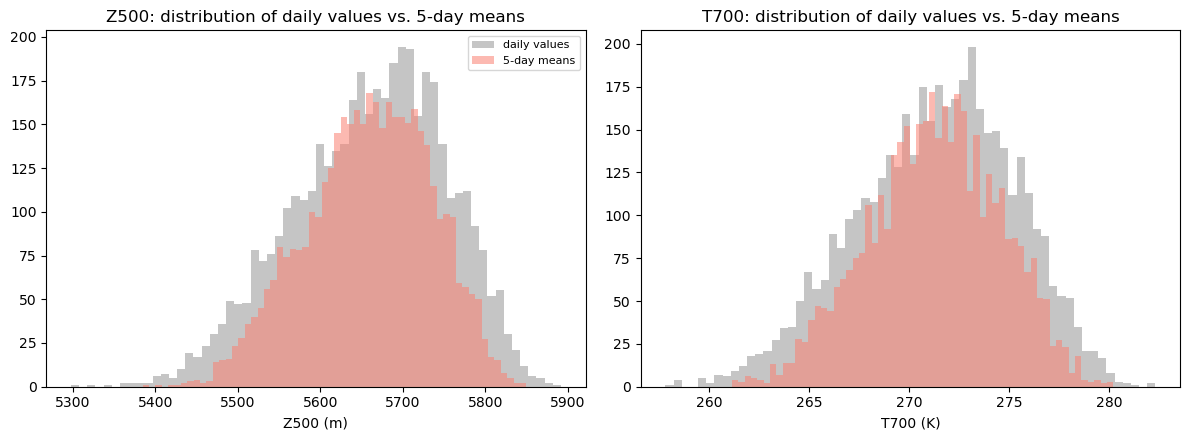

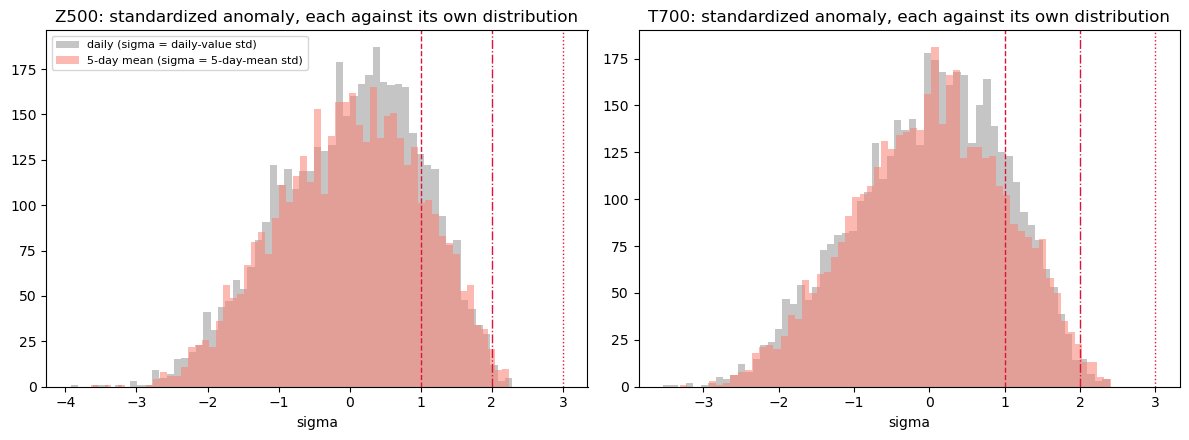

Skewness (should be 0 for a symmetric/Gaussian distribution):
  daily z500_sanom: -0.333   5-day-mean z500_sanom: -0.208
  daily t700_sanom: -0.308   5-day-mean t700_sanom: -0.166


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col, label, unit in zip(axes, ['z500', 't700'], ['Z500', 'T700'], ['m', 'K']):
    ax.hist(df[col], bins=60, color='grey', alpha=0.45, label='daily values')
    ax.hist(df_roll[col], bins=60, color='salmon', alpha=0.55, label='5-day means')
    ax.set_title(f'{label}: distribution of daily values vs. 5-day means')
    ax.set_xlabel(f'{label} ({unit})')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col, label in zip(axes, ['z500_sanom', 't700_sanom'], ['Z500', 'T700']):
    ax.hist(df[col], bins=60, color='grey', alpha=0.45, label='daily (sigma = daily-value std)')
    ax.hist(df_roll[col], bins=60, color='salmon', alpha=0.55, label='5-day mean (sigma = 5-day-mean std)')
    for sd, ls in zip(THRESHOLDS, ['--', '-.', ':']):
        ax.axvline(sd, color='crimson', linestyle=ls, linewidth=1)
    ax.set_title(f'{label}: standardized anomaly, each against its own distribution')
    ax.set_xlabel('sigma')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

print('Skewness (should be 0 for a symmetric/Gaussian distribution):')
for col in ['z500_sanom', 't700_sanom']:
    print(f'  daily {col}: {df[col].skew():+.3f}   5-day-mean {col}: {df_roll[col].skew():+.3f}')

## 7. Large events, standardized against the 5-day-mean distribution

Each day of `df_roll` already *is* a 5-day mean, so persistence is baked into the
quantity itself -- `min_duration=1` is the right choice here.

In [7]:
events_C = []
for col, label in VARS:
    sanom = df_roll[f'{col}_sanom'].values
    for thr in THRESHOLDS:
        ev = lib.find_events(df_roll.index, sanom, threshold=thr, min_duration=1, sign=SIGN, max_gap=MAX_GAP)
        ev.insert(0, 'threshold_sd', thr)
        ev.insert(0, 'variable', label)
        events_C.append(ev)

events_methodC = pd.concat(events_C, ignore_index=True)
events_methodC = events_methodC.sort_values(['variable', 'threshold_sd', 'start_date']).reset_index(drop=True)
assert len(events_methodC) > 0, 'no Method C events found -- check THRESHOLDS/data before continuing'
print(f"{len(events_methodC)} episodes found using the 5-day-mean distribution's own sigma")
events_methodC.groupby(['variable', 'threshold_sd']).agg(
    n_events=('duration_days', 'size'),
    mean_duration=('duration_days', 'mean'),
    max_duration=('duration_days', 'max'),
)

306 episodes found using the 5-day-mean distribution's own sigma


n_events  mean_duration  max_duration
variable                   threshold_sd                                       
500 hPa height (ridging)   1                  139       5.201439          18.0
                           2                   13       2.230769           4.0
700 hPa temperature (warm) 1                  137       5.262774          19.0
                           2                   17       2.470588           7.0

## 8. How uncertain are the event counts themselves?

Every count reported so far (95 Method A events, 306 Method C episodes, etc.) is a
point estimate from one 36-year sample. This re-runs the full
detrend-standardize-detect pipeline under a year-block bootstrap (same resampling
scheme as `bootstrap_climatology_std`: resample the 36 years with replacement, which
`find_events`'s segment-boundary logic handles correctly without any relabeling,
since no two Jan-Apr blocks are ever exactly 1 calendar day apart regardless of which
years get repeated or skipped) to give a confidence interval on the event count at
the loosest threshold, for both Method A and Method C.

In [8]:
def bootstrap_event_count(time_index, vals, window, threshold, min_duration, sign, max_gap,
                           n_boot=100, random_state=0):
    years = time_index.year.values
    uniq_years = np.unique(years)
    rng = np.random.default_rng(random_state)
    year_idx = {y: np.where(years == y)[0] for y in uniq_years}
    counts = np.empty(n_boot, dtype=int)
    for b in range(n_boot):
        draw = rng.choice(uniq_years, size=len(uniq_years), replace=True)
        idx = np.concatenate([year_idx[y] for y in draw])
        time_b = time_index[idx]
        vals_b = vals[idx]
        sanom_b, _ = lib.standardize_with_trend(time_b, vals_b, window=window, label='', verbose=False)
        ev_b = lib.find_events(time_b, sanom_b, threshold=threshold, min_duration=min_duration,
                                sign=sign, max_gap=max_gap)
        counts[b] = len(ev_b)
    return counts


N_BOOT_EVENTS = 100
loosest = min(THRESHOLDS)
for col, label in VARS:
    counts_A = bootstrap_event_count(df.index, df[col].values, window=CLIM_WINDOW, threshold=loosest,
                                      min_duration=5, sign=SIGN, max_gap=MAX_GAP, n_boot=N_BOOT_EVENTS)
    counts_C = bootstrap_event_count(df_roll.index, df_roll[col].values, window=CLIM_WINDOW, threshold=loosest,
                                      min_duration=1, sign=SIGN, max_gap=MAX_GAP, n_boot=N_BOOT_EVENTS)
    point_A = int(events_methodA[(events_methodA.variable == label) & (events_methodA.threshold_sd == loosest)].shape[0])
    point_C = int(events_methodC[(events_methodC.variable == label) & (events_methodC.threshold_sd == loosest)].shape[0])
    lo_A, hi_A = np.percentile(counts_A, [5, 95])
    lo_C, hi_C = np.percentile(counts_C, [5, 95])
    print(f'{label} (>= {loosest} sigma):')
    print(f'  Method A: point estimate {point_A}, 90% bootstrap CI [{lo_A:.0f}, {hi_A:.0f}] (n_boot={N_BOOT_EVENTS})')
    print(f'  Method C: point estimate {point_C}, 90% bootstrap CI [{lo_C:.0f}, {hi_C:.0f}] (n_boot={N_BOOT_EVENTS})')

500 hPa height (ridging) (>= 1 sigma):
  Method A: point estimate 48, 90% bootstrap CI [37, 53] (n_boot=100)
  Method C: point estimate 139, 90% bootstrap CI [131, 155] (n_boot=100)


700 hPa temperature (warm) (>= 1 sigma):
  Method A: point estimate 47, 90% bootstrap CI [41, 56] (n_boot=100)
  Method C: point estimate 137, 90% bootstrap CI [126, 148] (n_boot=100)


## 9. Percentile-based thresholds: a non-parametric cross-check

Both variables are measurably skewed (Section 6), so a "+1 sigma" cutoff doesn't
correspond to a fixed, comparable exceedance probability -- especially not between the
daily and 5-day-mean distributions, which don't share the same skew. This re-runs
event detection using empirical per-calendar-day percentiles of `df_roll` directly
(no normal-distribution assumption at all) and compares the resulting counts to the
sigma-based ones above. The percentile levels (90/95/99) are not meant to line up
1:1 with sigma 1/2/3 -- they're an independent check on whether the parametric
threshold is over- or under-counting events relative to a distribution-free
definition.

In [9]:
PERCENTILES = (90, 95, 99)
events_pct = []
for col, label in VARS:
    pct_clim = lib.percentile_climatology(df_roll.index, df_roll[col].values, window=CLIM_WINDOW,
                                           percentiles=PERCENTILES)
    for p in PERCENTILES:
        pct_lookup = lib.lookup_climatology(df_roll.index, pct_clim[p])
        rel = df_roll[col].values - pct_lookup  # >= 0 means at/above the p-th percentile for that calendar day
        ev = lib.find_events(df_roll.index, rel, threshold=0, min_duration=1, sign=SIGN, max_gap=MAX_GAP)
        ev.insert(0, 'percentile', p)
        ev.insert(0, 'variable', label)
        events_pct.append(ev)

events_methodC_pct = pd.concat(events_pct, ignore_index=True)
counts_pct = events_methodC_pct.groupby(['variable', 'percentile']).size().rename('n_events_percentile')
counts_sigma = events_methodC.groupby(['variable', 'threshold_sd']).size().rename('n_events_sigma')
print('Sigma-based counts (5-day-mean distribution):')
display(counts_sigma)
print('\nPercentile-based counts (5-day-mean distribution, distribution-free):')
display(counts_pct)

Sigma-based counts (5-day-mean distribution):


variable                    threshold_sd
500 hPa height (ridging)    1               139
                            2                13
700 hPa temperature (warm)  1               137
                            2                17
Name: n_events_sigma, dtype: int64


Percentile-based counts (5-day-mean distribution, distribution-free):


variable                    percentile
500 hPa height (ridging)    90            105
                            95             62
                            99             17
700 hPa temperature (warm)  90             93
                            95             54
                            99             23
Name: n_events_percentile, dtype: int64

## 10. How sensitive is event detection to MAX_GAP?

Rather than asserting `MAX_GAP=1`, estimate the extremal index
theta = n_clusters / n_exceedance_days across a range of gap tolerances: theta closer
to 1 means exceedances are nearly independent day to day (little clustering to
decluster), while a small theta / long implied cluster length means a lot of
clustering -- i.e. a larger MAX_GAP changes conclusions more at low theta. Evaluated
at the loosest sigma threshold (most exceedance days, most sensitive to the gap
choice).

In [10]:
for col, label in VARS:
    exceed = (df_roll[f'{col}_sanom'].values >= min(THRESHOLDS))
    table = lib.extremal_index_runs(df_roll.index, exceed, max_gaps=(0, 1, 2, 3))
    print(f'\n{label}:')
    display(table)


500 hPa height (ridging):


,max_gap,n_exceedance_days,n_clusters,extremal_index_theta,implied_mean_cluster_length
0,0,720,142,0.197222,5.070423
1,1,720,139,0.193056,5.179856
2,2,720,138,0.191667,5.217391
3,3,720,134,0.186111,5.373134



700 hPa temperature (warm):


,max_gap,n_exceedance_days,n_clusters,extremal_index_theta,implied_mean_cluster_length
0,0,718,140,0.194986,5.128571
1,1,718,137,0.190808,5.240876
2,2,718,134,0.186630,5.358209
3,3,718,131,0.182451,5.480916


## 11. Does it identify the same periods as Method A?

For each Method A event (daily-value sigma, >= 5 consecutive days), check whether a
Method C event (5-day-mean-distribution sigma) overlaps its dates at the same
threshold -- and vice versa.

In [11]:
print('Of each Method A event, how many have an overlapping Method C event?')
display(lib.match_rate(events_methodA, events_methodC, 'methodA', 'methodC'))

print('\nOf each Method C event, how many have an overlapping Method A event '
      "(the rest are episodes Method C catches that Method A's stricter daily "
      'persistence rule misses)?')
display(lib.match_rate(events_methodC, events_methodA, 'methodC', 'methodA'))

Of each Method A event, how many have an overlapping Method C event?


,variable,threshold_sd,n_methodA,matched_by_methodC
0,500 hPa height (ridging),1,48,48
1,700 hPa temperature (warm),1,47,47



Of each Method C event, how many have an overlapping Method A event (the rest are episodes Method C catches that Method A's stricter daily persistence rule misses)?


,variable,threshold_sd,n_methodC,matched_by_methodA
0,500 hPa height (ridging),1,139,47
1,500 hPa height (ridging),2,13,0
2,700 hPa temperature (warm),1,137,46
3,700 hPa temperature (warm),2,17,0


## 12. A ranked list of the largest events

Using the lowest threshold to capture every episode, ranked by peak 5-day-mean sigma.

**Caveat -- winner's curse.** Picking the top 10 out of ~100+ candidate episodes by a
noisy statistic (`peak_sanom`) selects *for* being extreme; the reported peak values
of the top-ranked events are likely somewhat inflated relative to their "true"
magnitude purely from that selection, not because they're necessarily more
exceptional than the next few down the list. `second_peak_sanom` (the event's
second-highest value) is shown alongside `peak_sanom` so it's visible whether an
event's extremity is a single-point spike (`second_peak_sanom` much lower than
`peak_sanom`) or a genuinely sustained plateau (the two are close) -- the latter is
less susceptible to this bias.

In [12]:
top_n = 10
loosest = min(THRESHOLDS)
for col, label in VARS:
    sub = events_methodC[(events_methodC.variable == label) & (events_methodC.threshold_sd == loosest)]
    ranked = sub.sort_values('peak_sanom', ascending=False).head(top_n)
    if len(ranked) < top_n:
        print(f'(only {len(ranked)} episodes found at the {loosest}-sigma threshold for {label})')
    print(f'\nTop {len(ranked)} largest {label} events by peak 5-day-mean sigma:')
    display(ranked[['start_date', 'end_date', 'duration_days', 'peak_sanom', 'second_peak_sanom', 'mean_sanom']])


Top 10 largest 500 hPa height (ridging) events by peak 5-day-mean sigma:


,start_date,end_date,duration_days,peak_sanom,second_peak_sanom,mean_sanom
54,2004-03-06,2004-03-23,18.0,2.242745,2.231816,1.728443
20,1994-04-13,1994-04-20,8.0,2.220058,2.217428,1.851177
12,1992-04-24,1992-04-28,5.0,2.185468,2.146443,1.825282
73,2009-01-08,2009-01-20,13.0,2.175892,2.161113,1.641847
3,1990-04-09,1990-04-14,6.0,2.163425,2.033996,1.669105
102,2015-03-24,2015-03-30,7.0,2.163206,2.074350,1.711756
104,2016-02-06,2016-02-16,11.0,2.129888,2.095513,1.844119
28,1996-04-23,1996-04-28,6.0,2.108231,2.085111,1.876015
9,1992-02-21,1992-02-28,8.0,2.096942,2.018014,1.700054
37,1999-04-14,1999-04-20,7.0,2.067349,2.021770,1.706444



Top 10 largest 700 hPa temperature (warm) events by peak 5-day-mean sigma:


,start_date,end_date,duration_days,peak_sanom,second_peak_sanom,mean_sanom
247,2015-02-02,2015-02-20,19.0,2.409926,2.376418,1.711194
207,2004-03-07,2004-03-24,18.0,2.343150,2.294934,1.829816
163,1992-04-24,1992-04-28,5.0,2.315845,2.124711,1.806410
171,1994-04-13,1994-04-21,9.0,2.267372,2.202531,1.831304
232,2012-04-19,2012-04-24,6.0,2.236670,2.196882,1.872742
279,2022-03-22,2022-03-27,6.0,2.216479,2.140358,1.695361
251,2016-02-07,2016-02-18,12.0,2.214858,2.165841,1.842158
210,2005-01-17,2005-01-23,7.0,2.193282,2.086958,1.801822
271,2020-04-24,2020-04-28,5.0,2.155285,2.118369,1.817567
249,2015-03-26,2015-03-31,6.0,2.119580,2.027021,1.660388


## 13. Conclusions

- **Event counts carry real sampling uncertainty** (Section 8): the point estimates reported throughout (e.g. 95 Method A events, ~300 Method C episodes) have 90% bootstrap CIs attached in Section 8 -- treat exact counts as approximate, not precise.
- **The standard deviation of the distribution of 5-day means is close to, but
  consistently smaller than, the standard deviation of daily values** (Section 4-5):
  the reduction is modest (CI reported in Section 5) because Z500/T700 are strongly
  autocorrelated day-to-day.
- **Fixing the mean/std inconsistency** (standardizing the mean against a detrended
  baseline while leaving std computed on raw, trend-contaminated values) made a
  measurable but small difference here -- printed per-variable in Sections 3-4 --
  because the fitted multi-decadal trend is small relative to synoptic day-to-day
  variance for this box/variable pair. It would matter more for a variable/region
  with a steeper or more significant trend.
- **Standardizing by the 5-day-mean distribution's own sigma, rather than requiring 5
  consecutive daily-value exceedances, surfaces largely the same periods** that
  Method A already flags (Section 11), plus additional ones where the smoothed
  5-day character stays strong even though an individual day dips below the
  daily-value threshold.
- **Percentile-based and sigma-based thresholds broadly agree** (Section 9); where
  they diverge, the skew measured in Section 6 is the likely explanation.
- **The chosen `MAX_GAP=1` is in a reasonable range** given the measured extremal
  index (Section 10), but event counts/durations are shown across gap values rather
  than asserted at a single choice.
- **Ranking "largest events" by peak sigma is a more useful scale than a binary
  threshold/persistence pass-fail**, but the ranked list should be read with the
  winner's-curse caveat (Section 12) in mind -- and, per the climate-science review,
  would be more defensible if cross-checked against an actual impact variable (e.g.
  the SNOTEL/SWE data already in this project directory) rather than taken on its
  own.

## 14. Export events for downstream validation

Writes the Method C (5-day-mean-distribution sigma) event list to its own CSV,
separate from Method A's, so `CA_snowmelt_events_detrend_5day.ipynb` can validate
Sierra SWE rapid-decline events against both event definitions side-by-side -- the
real test of whether Method C's looser, smoothed-persistence definition is actually a
more physically meaningful "large event," per the climate-science review's
recommendation.

**Update.** `CA_snowmelt_methodC_5daymean_std.ipynb` now exists and does exactly this on the snow side -- but note it does NOT smooth this notebook's Z500/T700 fields; it builds its own analogous Method A/Method C comparison for Sierra SWE rapid-decline events (per-station SWE change, not a gridded atmospheric field), since porting the "5-day mean" idea directly onto the existing SWE pipeline would have smoothed an already-derived, already-windowed quantity a second time (originally a 5-day-windowed one; the companion notebook has since switched to a 3-day-windowed min-in-window metric, but the same double-smoothing problem would apply either way). Its headline finding: Method C is a defensible, looser way to count snowmelt episodes (~5x more than a matched 1-day-diff control), but *ranking* episodes by peak sigma is not physically meaningful for that variable -- unlike Z500/T700, the network-decline fraction has severe seasonal heteroscedasticity (January's climatological variance is ~8x smaller than April's), which inverts a sigma-based ranking.

In [13]:
out_csv = DATA_DIR / 'ca_z500_t700_events_1990-2025_methodC_5daymean.csv'
events_methodC.to_csv(out_csv, index=False)
print(f'wrote {len(events_methodC)} Method C events to {out_csv}')

wrote 306 Method C events to /glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking/ca_z500_t700_events_1990-2025_methodC_5daymean.csv


## 15. Cleanup

In [14]:
ds.close()
print('dataset handle closed')

dataset handle closed
